# Task 3 · Data Cleaning: Messy E-commerce Orders

**Objective:** take a deliberately messy dataset and turn it into a clean, analysis-ready one, documenting every decision.
**Stack:** Python · pandas · numpy · Jupyter

**Dataset:** `messy_orders.csv` — ~1,000 e-commerce orders (customer, product, price, payment, delivery). It was generated by `generate_messy_data.py` with a fixed seed, with these defects injected on purpose: missing values (real nulls *and* placeholders like `?`, `-`, `N/A`), exact and near-duplicate rows, inconsistent labels (`M`/`male`/`MALE`), 4 date formats, currency symbols inside numbers, impossible values (age 999, negative quantity, 150% discount) and extreme outliers.

**Pipeline order and why**

| Step | What | Why in this position |
|---|---|---|
| 1 | Load + data quality report | Know what is wrong before touching anything |
| 2 | Standardisation | Placeholders → NaN, labels/dates/numbers unified. Must come first, otherwise duplicates and nulls hide behind formatting |
| 3 | Duplicates | Easier to detect after formatting is consistent |
| 4 | Missing data | After invalid values are turned into NaN, so they are treated like any other gap |
| 5 | Outliers | After imputation so fences are computed on complete data |
| 6 | Dtype correction | Final typing once values are clean |
| 7 | Before vs after | Prove the improvement with numbers |
| 8 | Save | Cleaned CSV + decision log |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

## 1 · Load data and build the data quality report

In [2]:
RAW_PATH = "messy_orders.csv"
raw = pd.read_csv(RAW_PATH)          # default read: nothing cleaned yet
print("Shape:", raw.shape)
raw.head(10)

Shape: (1045, 14)


,order_id,customer_id,customer_name,gender,age,city,order_date,product_category,unit_price,quantity,discount_pct,payment_method,delivery_status,total_amount
0,ORD-00363,1094,Rohan Patel,Female,42,Indore,04/05/2024,home and kitchen,"₹1,308.00",4,0,Credit Card,Cancelled,5232.00
1,ORD-00804,1076,NaN,M,51,Indore,14/10/2024,Books,₹503.00,1,0,UPI,Delivered,503.00
2,ORD-00267,-,Aarav Mishra,Female,23,Pune,2024-04-04,electronics,7913.00,3,0,UPI,Delivered,23739.00
3,ORD-00823,1063,Ritu Joshi,Male,39,Indore,21-Oct-2024,electronics,NaN,4,5,Upi,Delivered,27952.80
4,ORD-00571,1272,Rohan Verma,Female,27,Delhi,15/07/2024,Electronics,"11,725",3,0,debit card,shipped,35175.00
5,ORD-00572,1129,Kavya Verma,Male,24,Bhopal,"July 15, 2024",Electronics,5412.00,1,25,Upi,Shipped,4059.00
6,ORD-00508,1055,Pooja Jain,Male,-,indore,25-Jun-2024,Home & Kitchen,"₹2,263.00",1,15,Debit Card,Delivered,1923.55
7,ORD-00256,1057,Amit Gupta,FEMALE,19,bhopal,"April 01, 2024",clothing,1149.00,1,0,CC,returned,NaN
8,ORD-00523,1215,Aarav Jain,Male,21,Indore,2024-07-02,Clothing,"₹1,275.00",4,20,CC,Delivered,4080.00
9,ORD-00941,1057,Amit Gupta,Female,19,Bhopal,2024-12-10,electronics,"Rs. 7,793",1,15,Debit Card,delivered,6624.05


### Helper functions
Small reusable functions so the same checks can be run on the raw data (strings, symbols) **and** on the cleaned data (proper types) for a fair before/after comparison.

In [3]:
PLACEHOLDERS = {"", "na", "n/a", "nan", "null", "none", "?", "-", "--", "not available"}
DATE_FORMATS = ["%Y-%m-%d", "%d/%m/%Y", "%B %d, %Y", "%d-%b-%Y"]

def to_num(s):
    """Strip currency symbols, thousands separators and unit text, then convert to number."""
    cleaned = (s.astype(str).str.lower()
                 .str.replace(r"rs\.?|₹|,|\s|yrs?", "", regex=True))
    return pd.to_numeric(cleaned, errors="coerce")

def parse_date(x):
    """Try each known format; unparseable -> NaT. Day-first for numeric dates (Indian convention)."""
    if pd.isna(x):
        return pd.NaT
    if isinstance(x, pd.Timestamp):
        return x
    txt = str(x).strip()
    for fmt in DATE_FORMATS:
        try:
            return pd.to_datetime(txt, format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.NaT

def is_text(s):
    """True for text columns in both pandas 2 (object) and pandas 3 (str) dtypes."""
    return s.dtype == object or pd.api.types.is_string_dtype(s)

def placeholders_per_col(df):
    out = {}
    for c in df.columns:
        if is_text(df[c]):
            s = df[c].dropna().astype(str).str.strip().str.lower()
            out[c] = int(s.isin(PLACEHOLDERS).sum())
        else:
            out[c] = 0
    return pd.Series(out)

# Business rules for "impossible" values
RULES = {
    "age":          lambda s: (s < 18) | (s > 90),
    "quantity":     lambda s: s <= 0,
    "unit_price":   lambda s: s <= 0,
    "discount_pct": lambda s: (s < 0) | (s > 100),
    "total_amount": lambda s: s <= 0,
}

def range_anomalies(df):
    out = {col: int(rule(to_num(df[col])).sum()) for col, rule in RULES.items()}
    if pd.api.types.is_datetime64_any_dtype(df["order_date"]):
        bad = 0
    else:
        nn = df["order_date"].dropna()
        nn = nn[~nn.astype(str).str.strip().str.lower().isin(PLACEHOLDERS)]
        bad = int(nn.map(parse_date).isna().sum())
    out["order_date (unparseable)"] = bad
    return out

# What each column SHOULD be
EXPECTED = {"order_id": "id", "customer_id": "id", "customer_name": "text", "gender": "text",
            "age": "numeric", "city": "text", "order_date": "datetime", "product_category": "text",
            "unit_price": "numeric", "quantity": "numeric", "discount_pct": "numeric",
            "total_amount": "numeric", "payment_method": "text", "delivery_status": "text"}

def dtype_ok(s, kind):
    if kind == "datetime":
        return pd.api.types.is_datetime64_any_dtype(s)
    if kind == "numeric":
        return pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)
    # id / text: must not be numeric, must be text-like or categorical
    if pd.api.types.is_numeric_dtype(s):
        return False
    return is_text(s) or isinstance(s.dtype, pd.CategoricalDtype)

def dtype_table(df):
    cols = list(EXPECTED)
    return pd.DataFrame({"expected": pd.Series(EXPECTED),
                         "actual": df.dtypes.astype(str)[cols],
                         "correct": pd.Series({c: dtype_ok(df[c], EXPECTED[c]) for c in cols})}).loc[cols]

def snapshot(df):
    dt = dtype_table(df)
    return {
        "Row count": len(df),
        "Missing values (nulls + placeholders)": int(df.isna().sum().sum() + placeholders_per_col(df).sum()),
        "Exact duplicate rows": int(df.duplicated().sum()),
        "Duplicate order_id (same order twice)": int(df["order_id"].duplicated().sum()),
        "Impossible / unparseable values": sum(range_anomalies(df).values()),
        "Columns with correct dtype": f"{int(dt.correct.sum())}/{len(dt)}",
        "Dtype accuracy (%)": round(dt.correct.mean() * 100, 1),
    }

In [4]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "nulls": raw.isna().sum(),
    "placeholders (?, -, ...)": placeholders_per_col(raw),
    "unique values": raw.nunique(),
})
quality["total missing"] = quality["nulls"] + quality["placeholders (?, -, ...)"]
quality["missing %"] = (quality["total missing"] / len(raw) * 100).round(2)
display(quality)

print(f"Exact duplicate rows            : {raw.duplicated().sum()}")
print(f"Repeated order_id (any version) : {raw['order_id'].duplicated().sum()}")
print("\nValue-range anomalies (after peeking through the formatting):")
display(pd.Series(range_anomalies(raw), name="rows").to_frame())

,dtype,nulls,"placeholders (?, -, ...)",unique values,total missing,missing %
order_id,str,0,0,1000,0,0.00
customer_id,str,8,2,291,10,0.96
customer_name,str,14,6,533,20,1.91
gender,str,38,13,14,51,4.88
age,str,60,23,73,83,7.94
city,str,35,8,19,43,4.11
order_date,str,16,4,736,20,1.91
product_category,str,15,6,18,21,2.01
unit_price,str,42,10,933,52,4.98
quantity,str,25,5,14,30,2.87


Exact duplicate rows            : 20
Repeated order_id (any version) : 45

Value-range anomalies (after peeking through the formatting):


,rows
age,12
quantity,6
unit_price,4
discount_pct,7
total_amount,0
order_date (unparseable),0


### Data type issues
`dtype_table` compares what pandas loaded against what each column *should* be.

In [5]:
display(dtype_table(raw))

,expected,actual,correct
order_id,id,str,True
customer_id,id,str,True
customer_name,text,str,True
gender,text,str,True
age,numeric,str,False
city,text,str,True
order_date,datetime,str,False
product_category,text,str,True
unit_price,numeric,str,False
quantity,numeric,str,False


### Inconsistent labels (categorical columns)

In [6]:
for c in ["gender", "city", "product_category", "payment_method", "delivery_status"]:
    print(f"{c}: {raw[c].nunique()} distinct values ->", sorted(raw[c].dropna().astype(str).unique())[:25])
    print()
print("Date formats seen (sample):", raw["order_date"].dropna().sample(6, random_state=0).tolist())
print("Price formats seen (sample):", raw["unit_price"].dropna().sample(6, random_state=0).tolist())

gender: 14 distinct values -> [' Male', '-', '?', 'F', 'FEMALE', 'Female', 'Female ', 'M', 'MALE', 'Male', 'f', 'female', 'm', 'male']

city: 19 distinct values -> ['-', '?', 'Bangalore', 'Bengaluru', 'Bhopal', 'Delhi', 'INDORE', 'Indore', 'Indore ', 'MUMBAI', 'Mumbai', 'New Delhi', 'Pune', 'bangalore', 'bhopal', 'delhi', 'indore', 'mumbai', 'pune']

product_category: 18 distinct values -> ['-', '?', 'Beauty', 'Books', 'Clothes', 'Clothing', 'ELECTRONICS', 'Electronics', 'Home & Kitchen', 'Home&Kitchen', 'SPORTS', 'Sports', 'beauty ', 'books', 'clothing', 'electronics', 'home and kitchen', 'sports']

payment_method: 15 distinct values -> ['-', '?', 'CC', 'COD', 'Cash on Delivery', 'Credit Card', 'Debit Card', 'Net Banking', 'UPI', 'Upi', 'cod', 'credit card', 'debit card', 'net banking', 'upi']

delivery_status: 17 distinct values -> ['-', '?', 'CANCELLED', 'Cancelled', 'DELIVERED', 'Delivered', 'PENDING', 'Pending', 'RETURNED', 'Returned', 'SHIPPED', 'Shipped', 'cancelled', 'delivered

### Findings from the quality report
1. **Missing data hides in two forms**: real nulls *and* placeholder text (`?`, `-`). `isna()` alone under-counts.
2. **Duplicates**: exact copies plus *near* duplicates (same `order_id`, different formatting/nulls) that `duplicated()` would miss. Some copies only look different because of formatting, so more exact duplicates appear after standardisation (step 3) than the raw count shows.
3. **Labels** such as gender, city, payment method and category each exist in many spellings.
4. **Types**: IDs and dates are stored wrongly; numeric columns are `object` because of `₹`, `Rs.`, commas, `yrs` and `?`.
5. **Impossible values**: ages like -5 or 999, zero/negative quantities, discounts over 100%.
6. **Extreme outliers** in quantity and unit price.

From here on, every change is recorded in a **decision log** so the whole cleaning is auditable.

## 2 · Standardisation

In [7]:
df = raw.copy()
decision_log = []

def log_step(step, column, issue, action, rows):
    decision_log.append({"step": step, "column": column, "issue": issue,
                         "action": action, "rows_affected": int(rows)})

### 2.1 Whitespace and placeholder tokens → real `NaN`
**Decision:** trim whitespace on every text column and convert placeholder tokens (`?`, `-`, `N/A`, …) to `NaN`. Without this, `?` would be counted as a valid category/number and break numeric conversion. Every later missing-data step then works on one consistent representation.

In [8]:
n_placeholders = int(placeholders_per_col(df).sum())
for c in [c for c in df.columns if is_text(df[c])]:
    s = df[c].where(df[c].isna(), df[c].astype(str).str.strip())
    df[c] = s.mask(s.astype(str).str.lower().isin(PLACEHOLDERS))
log_step("Standardise", "ALL text columns", "whitespace + placeholder tokens (?, -, N/A)",
         "strip whitespace; placeholders -> NaN", n_placeholders)
print(f"{n_placeholders} placeholder tokens converted to NaN. Total nulls now: {int(df.isna().sum().sum())}")

122 placeholder tokens converted to NaN. Total nulls now: 496

### 2.2 Inconsistent labels → one canonical value
**Decision:** normalise to lowercase/trimmed keys, then map every variant to a canonical label with an explicit dictionary. An explicit mapping beats fuzzy matching here because the label sets are small and a wrong merge would be silent. The function prints any value that is **not** covered by the mapping, so nothing slips through unnoticed.

In [9]:
def norm(s):
    return (s.str.lower().str.replace("&", " and ", regex=False)
             .str.replace(r"\s+", " ", regex=True).str.strip())

def standardise(col, mapping):
    key = norm(df[col])
    out = key.map(mapping)
    unmapped = sorted(key[out.isna() & key.notna()].unique())
    changed = int((df[col].notna() & (df[col] != out)).sum())
    print(f"{col:17s}: {df[col].nunique():>2} variants -> {out.nunique()} labels | unmapped: {unmapped}")
    log_step("Standardise", col, f"{df[col].nunique()} spelling variants",
             f"mapped to {out.nunique()} canonical labels", changed)
    df[col] = out

standardise("gender", {"male": "Male", "m": "Male", "female": "Female", "f": "Female"})
standardise("city", {"indore": "Indore", "bhopal": "Bhopal", "mumbai": "Mumbai", "pune": "Pune",
                     "delhi": "Delhi", "new delhi": "Delhi", "bangalore": "Bangalore", "bengaluru": "Bangalore"})
standardise("product_category", {"electronics": "Electronics", "clothing": "Clothing", "clothes": "Clothing",
                                 "home and kitchen": "Home & Kitchen", "books": "Books",
                                 "beauty": "Beauty", "sports": "Sports"})
standardise("payment_method", {"upi": "UPI", "credit card": "Credit Card", "cc": "Credit Card",
                               "debit card": "Debit Card", "net banking": "Net Banking",
                               "cash on delivery": "Cash on Delivery", "cod": "Cash on Delivery"})
standardise("delivery_status", {"delivered": "Delivered", "shipped": "Shipped", "pending": "Pending",
                                "cancelled": "Cancelled", "canceled": "Cancelled", "returned": "Returned"})

# Names: collapse repeated spaces, Title Case
before_names = df["customer_name"].copy()
df["customer_name"] = df["customer_name"].str.replace(r"\s+", " ", regex=True).str.strip().str.title()
log_step("Standardise", "customer_name", "mixed case / extra spaces", "collapse spaces + Title Case",
         (before_names.notna() & (before_names != df["customer_name"])).sum())

gender           : 10 variants -> 2 labels | unmapped: []
city             : 16 variants -> 6 labels | unmapped: []
product_category : 16 variants -> 6 labels | unmapped: []
payment_method   : 13 variants -> 5 labels | unmapped: []
delivery_status  : 15 variants -> 5 labels | unmapped: []


### 2.3 Numbers stored as text → numeric
**Decision:** strip `₹`, `Rs.`, thousands commas and the `yrs` suffix, then convert with `pd.to_numeric`. Anything still unparseable becomes `NaN` (and is handled in the missing-data step) rather than crashing or being silently kept as text.

In [10]:
num_cols = ["customer_id", "age", "quantity", "unit_price", "discount_pct", "total_amount"]
for col in num_cols:
    nn_before = int(df[col].notna().sum())
    df[col] = to_num(df[col])
    lost = nn_before - int(df[col].notna().sum())
    log_step("Standardise", col, "numbers stored as text (symbols/commas/units)", "stripped symbols, to_numeric", nn_before)
    print(f"{col:13s}: converted, {lost} values unparseable -> NaN")

customer_id  : converted, 0 values unparseable -> NaN
age          : converted, 0 values unparseable -> NaN
quantity     : converted, 0 values unparseable -> NaN
unit_price   : converted, 0 values unparseable -> NaN
discount_pct : converted, 0 values unparseable -> NaN
total_amount : converted, 0 values unparseable -> NaN


### 2.4 Mixed date formats → `datetime`
**Decision:** four formats exist (`2024-03-15`, `15/03/2024`, `March 15, 2024`, `15-Mar-2024`). I parse each with an **explicit format list** instead of `pd.to_datetime(..., errors="coerce")`. For slash dates, an automatic parser would guess month-first and silently misread `05/04/2024`. Here numeric dates are read **day-first**, the standard in India.

In [11]:
nn = int(df["order_date"].notna().sum())
df["order_date"] = pd.to_datetime(df["order_date"].map(parse_date))
log_step("Standardise", "order_date", "4 different date formats", "explicit-format parsing, day-first", nn)
print("Parsed dates:", int(df["order_date"].notna().sum()), "| range:", df["order_date"].min().date(), "->", df["order_date"].max().date())

Parsed dates: 1025 | range: 2024-01-01 -> 2024-12-30


## 3 · Duplicate removal
Two kinds are handled:
1. **Exact duplicates**: identical in every column → drop, keep the first.
2. **Near duplicates**: the *same `order_id`* appears more than once but copies differ (one has nulls the other doesn't). An order ID is a primary key, so there can be only one row per ID. **Decision:** keep the version with the **fewest missing values**, so no information is lost.

In [12]:
n_start = len(df)

exact = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
log_step("Duplicates", "ALL", "exact duplicate rows", "drop_duplicates (keep first)", exact)

near = int(df["order_id"].duplicated().sum())
df["_nulls"] = df.isna().sum(axis=1)
df = (df.sort_values(["order_id", "_nulls"])
        .drop_duplicates("order_id", keep="first")
        .drop(columns="_nulls")
        .reset_index(drop=True))
log_step("Duplicates", "order_id", "same order_id, rows differ slightly", "keep copy with fewest nulls", near)

print(f"Exact duplicates removed       : {exact}")
print(f"Near duplicates (same order_id): {near}")
print(f"Rows: {n_start} -> {len(df)}  (removed {n_start - len(df)})")
assert df["order_id"].is_unique

Exact duplicates removed       : 30
Near duplicates (same order_id): 15
Rows: 1045 -> 1000  (removed 45)


## 4 · Missing data handling
First, values that are **impossible** (age 999, quantity −2, discount 150%) are set to `NaN`: they are errors, so they are treated as missing instead of being trusted.

### Strategy per column

| Column | Strategy | Justification |
|---|---|---|
| `order_id` / `customer_id` | **Delete row** | Primary keys. A row you cannot identify has no analytical value and imputing an ID would fabricate a customer |
| `order_date` | **Forward fill** (after sorting by `order_id`) | Order IDs are issued sequentially, so dates are chronological with the ID. A missing date is almost always the same day as the previous order (`bfill` only for the very first row) |
| `customer_name`, `gender`, `age`, `city` | **Fill from the same customer's other orders**, then fallback | These are attributes of the *customer*, not the order. A repeat customer's other rows give the true value. This is far more accurate than a global statistic. Fallback below |
| `age` (fallback) | **Median** | Ages are right-skewed; median is robust to the remaining outliers |
| `gender`, `city`, `customer_name` (fallback) | **Constant "Unknown"** | Using the mode would bias counts toward the majority group and invent facts about people |
| `product_category`, `delivery_status` | **Constant "Unknown"** | Cannot be inferred from other columns. A guess would distort category and fulfilment analysis |
| `payment_method` | **Mode** | Few categories, one dominant (UPI). Low risk, and keeps the column complete |
| `quantity` | **Median** (rounded) | Discrete and skewed. The median is a plausible whole-number order size |
| `unit_price` | **Median of the same product category** | Price depends heavily on category (Books vs Electronics). A global mean would be badly wrong |
| `discount_pct` | **0** | No recorded discount most plausibly means no discount (0% is the most common value) |
| `total_amount` | **Derived**: `quantity × unit_price × (1 − discount/100)` | It is a formula of other columns, so calculating beats estimating |

In [13]:
# 4.1 impossible values -> NaN
for col in ["age", "quantity", "unit_price", "discount_pct"]:
    bad = RULES[col](df[col])
    df.loc[bad, col] = np.nan
    log_step("Missing data", col, "impossible value (outside business rule)", "set to NaN, then imputed", bad.sum())
    print(f"{col:13s}: {int(bad.sum())} impossible values -> NaN")

print("\nNulls per column before handling:")
display(df.isna().sum()[lambda s: s > 0].to_frame("nulls"))

age          : 12 impossible values -> NaN
quantity     : 6 impossible values -> NaN
unit_price   : 4 impossible values -> NaN
discount_pct : 7 impossible values -> NaN

Nulls per column before handling:


,nulls
customer_id,10
customer_name,20
gender,48
age,93
city,39
order_date,19
product_category,19
unit_price,51
quantity,35
discount_pct,66


In [14]:
rows_before = len(df)

# 4.2 delete rows without a key
no_key = df["customer_id"].isna() | df["order_id"].isna()
df = df[~no_key].copy()
log_step("Missing data", "customer_id", "missing primary key", "delete row", no_key.sum())

# helper: fill + log
def fill(col, values, strategy):
    n = int(df[col].isna().sum())
    df[col] = df[col].fillna(values)
    log_step("Missing data", col, f"{n} missing", strategy, n)

# 4.3 order_date: forward fill on chronological order_id
df = df.sort_values("order_id").reset_index(drop=True)
n = int(df["order_date"].isna().sum())
df["order_date"] = df["order_date"].ffill().bfill()
log_step("Missing data", "order_date", f"{n} missing", "forward fill by order_id (bfill for first row)", n)

# 4.4 customer attributes: first from the same customer, then fallback
for col in ["customer_name", "gender", "age", "city"]:
    from_cust = df.groupby("customer_id")[col].transform("first")
    fill(col, from_cust, "filled from same customer's other orders")

fill("age", df["age"].median(), "median (fallback)")
fill("gender", "Unknown", "constant 'Unknown' (fallback)")
fill("city", "Unknown", "constant 'Unknown' (fallback)")
fill("customer_name", "Unknown", "constant 'Unknown' (fallback)")

# 4.5 order attributes
fill("product_category", "Unknown", "constant 'Unknown'")
fill("delivery_status", "Unknown", "constant 'Unknown'")
fill("payment_method", df["payment_method"].mode()[0], "mode")
fill("quantity", round(df["quantity"].median()), "median (rounded)")
fill("unit_price", df.groupby("product_category")["unit_price"].transform("median"), "median of same product category")
fill("unit_price", df["unit_price"].median(), "global median (fallback)")
fill("discount_pct", 0, "constant 0 (no discount recorded)")
derived = (df["quantity"] * df["unit_price"] * (1 - df["discount_pct"] / 100)).round(2)
fill("total_amount", derived, "derived from quantity x price x (1 - discount)")

print(f"Rows deleted for missing key : {rows_before - len(df)}")
print(f"Nulls remaining in dataset   : {int(df.isna().sum().sum())}")
assert df.isna().sum().sum() == 0

Rows deleted for missing key : 10
Nulls remaining in dataset   : 0


## 5 · Outlier detection

**Method:** IQR rule (Q1 − 1.5·IQR, Q3 + 1.5·IQR). Z-score (|z| > 3) is computed alongside for comparison. IQR is the primary method because the data is skewed and the outliers themselves inflate the mean and standard deviation, which makes z-scores *miss* them (masking effect). IQR uses quartiles, which are not affected by extremes.

A detail that matters: `unit_price` is **not comparable across categories** (a ₹8,000 phone is normal, a ₹8,000 book is not), so price outliers are checked *within each product category*.

In [15]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

def z_outliers(s, thr=3):
    return ((s - s.mean()) / s.std()).abs() > thr

def iqr_by_group(col, by):
    def f(s):
        lo, hi = iqr_bounds(s)
        return (s < lo) | (s > hi)
    return df.groupby(by)[col].transform(f).astype(bool)

rows = []
for col in ["age", "quantity", "unit_price", "total_amount"]:
    lo, hi = iqr_bounds(df[col])
    rows.append({"column": col, "IQR lower": round(lo, 1), "IQR upper": round(hi, 1),
                 "IQR outliers (global)": int(((df[col] < lo) | (df[col] > hi)).sum()),
                 "Z-score outliers (|z|>3)": int(z_outliers(df[col]).sum()),
                 "IQR outliers (within category)": int(iqr_by_group(col, "product_category").sum())
                                                   if col in ("unit_price", "total_amount") else "-"})
display(pd.DataFrame(rows).set_index("column"))

,IQR lower,IQR upper,IQR outliers (global),Z-score outliers (|z|>3),IQR outliers (within category)
column,,,,,
age,4.6,59.6,3,3,-
quantity,-2.0,6.0,8,8,-
unit_price,-2250.6,5642.4,191,6,11
total_amount,-7015.6,14653.7,118,7,37


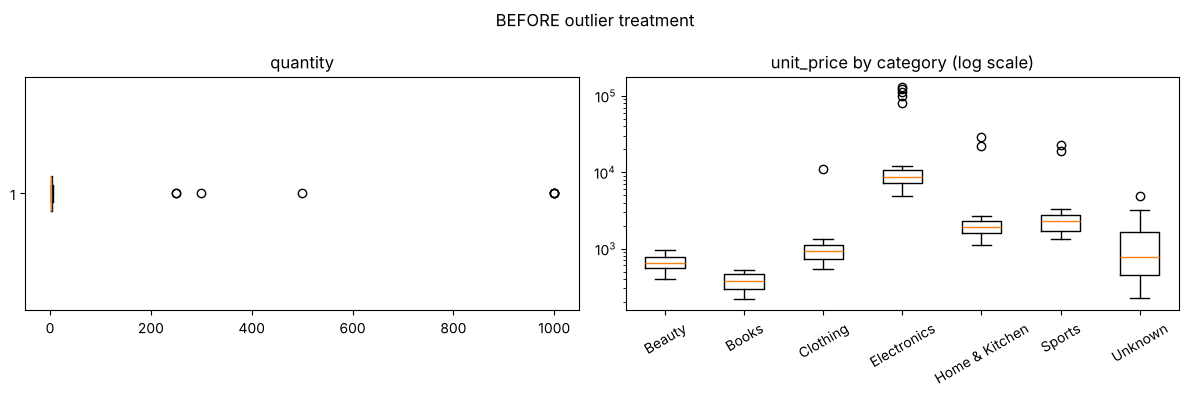

In [16]:
def plot_boxes(title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].boxplot(df["quantity"], vert=False)
    ax[0].set_title("quantity")
    names = sorted(df["product_category"].unique())
    ax[1].boxplot([df.loc[df.product_category == n, "unit_price"] for n in names])
    ax[1].set_xticks(range(1, len(names) + 1)); ax[1].set_xticklabels(names, rotation=30)
    ax[1].set_yscale("log"); ax[1].set_title("unit_price by category (log scale)")
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_boxes("BEFORE outlier treatment")

### Decision per column

| Column | Decision | Justification |
|---|---|---|
| `age` | **Retain** | Impossible ages were already removed in step 4. Remaining values are plausible adults (19–70), so extremes are genuine, not errors |
| `quantity` | **Cap** at IQR upper fence | Typical orders are 1–5 units. Values like 250–999 are data-entry errors, not bulk buyers. Removing the rows would also discard valid customer/price information, so capping keeps the order while limiting its influence |
| `unit_price` | **Cap** at the within-category IQR upper fence | Prices ×12 above the category norm are clear entry errors (extra digit). Capping per category fixes them without flagging legitimate expensive electronics |
| `total_amount` | **Retain flagged values, then recompute** | High totals are a natural result of price × quantity in expensive categories (genuine, right-skewed). After capping inputs, the column is recalculated so it stays arithmetically consistent |

quantity   : capped 8 values at 6
unit_price : capped 11 values at their category fence
age        : 3 IQR-flagged values retained
total      : 132 totals recalculated for consistency


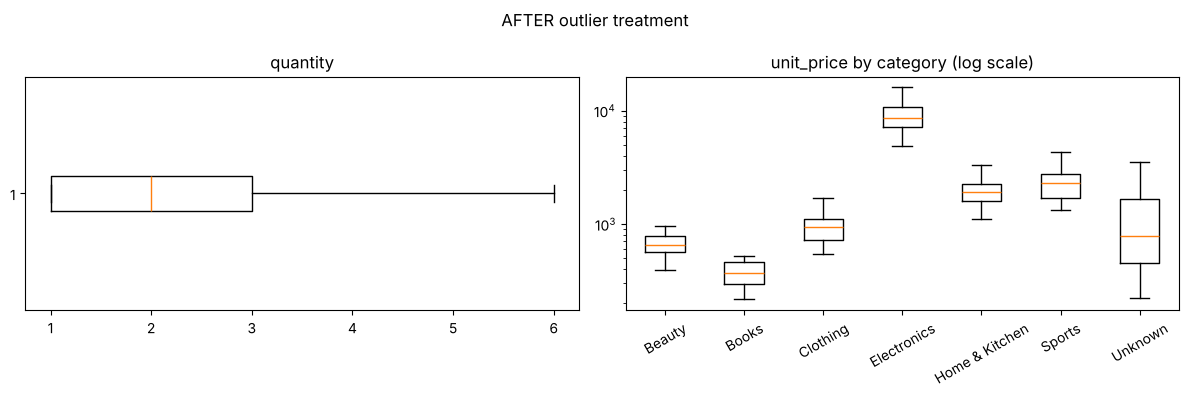

In [17]:
# quantity: cap at global IQR upper fence (rounded down to a whole unit)
_, hi_q = iqr_bounds(df["quantity"])
cap_q = int(np.floor(hi_q))
n_q = int((df["quantity"] > cap_q).sum())
df["quantity"] = df["quantity"].clip(upper=cap_q)
log_step("Outliers", "quantity", f"extreme values (> {cap_q})", f"capped at IQR upper fence ({cap_q})", n_q)

# unit_price: cap at within-category upper fence
fence = df.groupby("product_category")["unit_price"].transform(lambda s: iqr_bounds(s)[1])
n_p = int((df["unit_price"] > fence).sum())
df["unit_price"] = df["unit_price"].clip(upper=fence)
log_step("Outliers", "unit_price", "extreme values vs own category", "capped at category IQR upper fence", n_p)

# age retained
lo_a, hi_a = iqr_bounds(df["age"])
n_a = int(((df["age"] < lo_a) | (df["age"] > hi_a)).sum())
log_step("Outliers", "age", "IQR-flagged but plausible", "retained", n_a)

# total_amount: recompute so it is consistent with the treated inputs
old_total = df["total_amount"].copy()
df["total_amount"] = (df["quantity"] * df["unit_price"] * (1 - df["discount_pct"] / 100)).round(2)
n_t = int((~np.isclose(old_total, df["total_amount"])).sum())
log_step("Outliers", "total_amount", "inconsistent after capping / imputation", "recomputed from cleaned inputs", n_t)

print(f"quantity   : capped {n_q} values at {cap_q}")
print(f"unit_price : capped {n_p} values at their category fence")
print(f"age        : {n_a} IQR-flagged values retained")
print(f"total      : {n_t} totals recalculated for consistency")
plot_boxes("AFTER outlier treatment")

## 6 · Data type correction
**Decision:**
- IDs → `string` (they are labels, never used in arithmetic, and a numeric type would invite meaningless sums/means)
- Low-cardinality text → `category` (less memory, explicit set of allowed values)
- Counts (`age`, `quantity`) → nullable `Int64` (whole numbers)
- Money and percentages → `float64`
- Dates → `datetime64[ns]`

In [18]:
df["customer_id"] = df["customer_id"].astype("Int64").astype("string")
df["age"] = df["age"].round().astype("Int64")
df["quantity"] = df["quantity"].round().astype("Int64")

df = df.astype({
    "order_id": "string", "customer_name": "string",
    "gender": "category", "city": "category", "product_category": "category",
    "payment_method": "category", "delivery_status": "category",
    "unit_price": "float64", "discount_pct": "float64", "total_amount": "float64",
})
df["order_date"] = pd.to_datetime(df["order_date"])
log_step("Dtypes", "ALL", "wrong storage types", "IDs->string, labels->category, counts->Int64, money->float, dates->datetime", len(df.columns))

df = df.sort_values("order_id").reset_index(drop=True)
display(dtype_table(df))
df.info()

,expected,actual,correct
order_id,id,string,True
customer_id,id,string,True
customer_name,text,string,True
gender,text,category,True
age,numeric,Int64,True
city,text,category,True
order_date,datetime,datetime64[us],True
product_category,text,category,True
unit_price,numeric,float64,True
quantity,numeric,Int64,True


<class 'pandas.DataFrame'>
RangeIndex: 990 entries, 0 to 989
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          990 non-null    string        
 1   customer_id       990 non-null    string        
 2   customer_name     990 non-null    string        
 3   gender            990 non-null    category      
 4   age               990 non-null    Int64         
 5   city              990 non-null    category      
 6   order_date        990 non-null    datetime64[us]
 7   product_category  990 non-null    category      
 8   unit_price        990 non-null    float64       
 9   quantity          990 non-null    Int64         
 10  discount_pct      990 non-null    float64       
 11  payment_method    990 non-null    category      
 12  delivery_status   990 non-null    category      
 13  total_amount      990 non-null    float64       
dtypes: Int64(2), category(5), datetime64[

## 7 · Before vs. after
Both tables use the **same functions** on the raw and cleaned frames, so the comparison is like-for-like.

In [19]:
summary = pd.DataFrame({"Before": snapshot(raw), "After": snapshot(df)})
summary.index.name = "Metric"
display(summary)

print("\nDtype detail per column:")
dt_cmp = dtype_table(raw)[["expected", "actual", "correct"]].join(
         dtype_table(df)[["actual", "correct"]], lsuffix="_before", rsuffix="_after")
display(dt_cmp)

,Before,After
Metric,,
Row count,1045,990
Missing values (nulls + placeholders),496,0
Exact duplicate rows,20,0
Duplicate order_id (same order twice),45,0
Impossible / unparseable values,29,0
Columns with correct dtype,8/14,14/14
Dtype accuracy (%),57.1,100.0



Dtype detail per column:


,expected,actual_before,correct_before,actual_after,correct_after
order_id,id,str,True,string,True
customer_id,id,str,True,string,True
customer_name,text,str,True,string,True
gender,text,str,True,category,True
age,numeric,str,False,Int64,True
city,text,str,True,category,True
order_date,datetime,str,False,datetime64[us],True
product_category,text,str,True,category,True
unit_price,numeric,str,False,float64,True
quantity,numeric,str,False,Int64,True


In [20]:
miss_cmp = pd.DataFrame({
    "nulls + placeholders (before)": raw.isna().sum() + placeholders_per_col(raw),
    "nulls (after)": df.isna().sum(),
})
display(miss_cmp)
display(pd.Series(range_anomalies(df), name="impossible values AFTER cleaning").to_frame())

,nulls + placeholders (before),nulls (after)
order_id,0,0
customer_id,10,0
customer_name,20,0
gender,51,0
age,83,0
city,43,0
order_date,20,0
product_category,21,0
unit_price,52,0
quantity,30,0


,impossible values AFTER cleaning
age,0
quantity,0
unit_price,0
discount_pct,0
total_amount,0
order_date (unparseable),0


## 8 · Save outputs and validate

In [21]:
OUT_PATH = "cleaned_orders.csv"
df.to_csv(OUT_PATH, index=False, date_format="%Y-%m-%d")

log_df = pd.DataFrame(decision_log)
log_df.to_csv("cleaning_decision_log.csv", index=False)
summary.to_csv("before_after_summary.csv")

# validation: reload the file and re-check
chk = pd.read_csv(OUT_PATH, parse_dates=["order_date"], dtype={"order_id": "string", "customer_id": "string"})
assert chk.shape == df.shape
assert chk.isna().sum().sum() == 0
assert chk.duplicated().sum() == 0 and chk["order_id"].is_unique
assert sum(range_anomalies(chk).values()) == 0
print(f"Saved {OUT_PATH}: {chk.shape[0]} rows x {chk.shape[1]} columns. All validation checks passed.")

Saved cleaned_orders.csv: 990 rows x 14 columns. All validation checks passed.


### Full decision log (every cleaning action, with the number of rows it touched)

In [22]:
pd.set_option("display.max_colwidth", 70)
log_df

,step,column,issue,action,rows_affected
0,Standardise,ALL text columns,"whitespace + placeholder tokens (?, -, N/A)",strip whitespace; placeholders -> NaN,122
1,Standardise,gender,10 spelling variants,mapped to 2 canonical labels,366
2,Standardise,city,16 spelling variants,mapped to 6 canonical labels,424
3,Standardise,product_category,16 spelling variants,mapped to 6 canonical labels,474
4,Standardise,payment_method,13 spelling variants,mapped to 5 canonical labels,432
5,Standardise,delivery_status,15 spelling variants,mapped to 5 canonical labels,451
6,Standardise,customer_name,mixed case / extra spaces,collapse spaces + Title Case,629
7,Standardise,customer_id,numbers stored as text (symbols/commas/units),"stripped symbols, to_numeric",1035
8,Standardise,age,numbers stored as text (symbols/commas/units),"stripped symbols, to_numeric",962
9,Standardise,quantity,numbers stored as text (symbols/commas/units),"stripped symbols, to_numeric",1015


## Summary
- Started from a messy file with hidden placeholders, duplicate and near-duplicate orders, 4 date formats, text-formatted numbers, impossible values and extreme outliers.
- Every column got an individually justified strategy: deletion only for rows with no key, derivation for formulas, customer-level lookup for customer attributes, median/mode only where the column's distribution justifies it, and `"Unknown"` where a guess would distort analysis.
- Outliers were treated by type: capped where they are clear entry errors, retained where they are genuine.
- The cleaned dataset passes automated checks (no nulls, no duplicates, no impossible values, correct dtypes) and is saved as `cleaned_orders.csv`, with a `cleaning_decision_log.csv` for audit.

**Limitations worth stating:** imputed values (medians, modes) reduce variance slightly; the `"Unknown"` buckets should be reported alongside any category analysis; and the day-first date assumption should be confirmed with the data owner on real data.